# Lab Day 10 — Qwen3-VL-4B / Road Damage Grounding (E0–E5)

Bản thống nhất E0/E1/E2/E3/E4 và reward E5, dựa trên notebook gốc. Thay đổi: `model.visual` không NF4, projector FP32, LoRA target chính xác, LR riêng cho projector, checkpoint và đánh giá nhất quán, E4 r=4 vs r=64. **E5 mới có reward + unit tests; chưa triển khai GRPO bonus**. Không sửa `scripts/` và `tests/`. Chạy các code cell theo thứ tự; E1–E4 tốn GPU và có thể chọn chạy từng cell. Tải dữ liệu và chứng cứ có trong `work/`, `report/`.

In [4]:
!git clone https://github.com/pddczpl/K4-Track-4-Day10-PhanDanhDat-02627-VisionLanguageModel


Cloning into 'K4-Track-4-Day10-PhanDanhDat-02627-VisionLanguageModel'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 34 (delta 1), reused 0 (delta 0), pack-reused 30 (from 1)
Receiving objects: 100% (34/34), 31.66 KiB | 15.83 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [5]:
# Cell 1 — Chuyển vào repo đã clone trên Colab
from pathlib import Path
import os
REPO = Path('/content/K4-Track-4-Day10-PhanDanhDat-02627-VisionLanguageModel')
assert REPO.exists(), f'Bạn cần clone repo trước: {REPO}'
os.chdir(REPO)
print('Working directory:', Path.cwd())

Working directory: /content/K4-Track-4-Day10-PhanDanhDat-02627-VisionLanguageModel


## 0. Môi trường (Colab T4)

Kiểm tra GPU T4, cài đặt thư viện cần thiết, nạp Kaggle credentials qua Colab Secrets và mount Google Drive.

In [6]:
# Cell 3 — Thiết lập Colab, dùng requirements ghim theo repo
import sys, subprocess, torch
assert torch.cuda.is_available(), 'Chọn Runtime > Change runtime type > GPU trước.'
print('GPU:', torch.cuda.get_device_name(0))
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-colab.txt'], check=True)
subprocess.run([sys.executable, '-m', 'pytest', '-q'], check=True)
print('Lưu ý: restart Runtime nếu bạn vừa nâng cấp transformers hoặc peft.')

GPU: NVIDIA A100-SXM4-80GB
Lưu ý: restart Runtime nếu bạn vừa nâng cấp transformers hoặc peft.


In [7]:
# Kaggle credentials qua Google Colab Secrets (KHÔNG ghi khoá vào notebook)
import os
from google.colab import userdata

try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("✓ Đã nạp thành công KAGGLE_USERNAME và KAGGLE_KEY từ Colab Secrets!")
except Exception as e:
    print("Lưu ý: Nếu chạy trên Google Colab, hãy click vào biểu tượng 'Chìa khóa' (Secrets) ở thanh bên trái, thêm: KAGGLE_USERNAME và KAGGLE_KEY.")
    print("Chi tiết lỗi:", e)

# Mount Google Drive để sao lưu checkpoint adapter định kỳ
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_BACKUP = "/content/drive/MyDrive/lab_day10_backup"
    os.makedirs(DRIVE_BACKUP, exist_ok=True)
    print(f"✓ Đã mount Google Drive. Thư mục sao lưu: {DRIVE_BACKUP}")
except Exception as e:
    print("Bỏ qua mount Google Drive:", e)

✓ Đã nạp thành công KAGGLE_USERNAME và KAGGLE_KEY từ Colab Secrets!
Mounted at /content/drive
✓ Đã mount Google Drive. Thư mục sao lưu: /content/drive/MyDrive/lab_day10_backup


## 1. Dữ liệu: tải và chia split

Tải bộ dữ liệu road damage và chia split theo phiên quay (session) cố định để chống rò rỉ frame liền kề.

In [8]:
# Cell 6 — Chỉ tải/split nếu files chưa có, tránh ghi đè dataset_version
import subprocess, sys
from pathlib import Path
splits = [Path('data/splits') / f'{part}.jsonl' for part in ('train','val','test')]
if not all(p.exists() for p in splits):
    subprocess.run([sys.executable, 'scripts/prepare_data.py', '--kaggle'], check=True)
else:
    print('✓ Đã có dữ liệu đã chia split; không tạo lại.')

In [9]:
# Đọc các split, kiểm tra thống kê và xác nhận tính độc lập giữa các phiên quay
import json
from pathlib import Path
from scripts.labcommon import read_jsonl, CLASSES

train_entries = read_jsonl("data/splits/train.jsonl")
val_entries = read_jsonl("data/splits/val.jsonl")
test_entries = read_jsonl("data/splits/test.jsonl")
meta_data = json.loads(Path("data/splits/meta.json").read_text(encoding="utf-8"))

print(f"Dataset version: {meta_data['dataset_version']}")
print(f"Số lượng ảnh: Train = {len(train_entries)}, Val = {len(val_entries)}, Test = {len(test_entries)}")

for split_name, entries in [("Train", train_entries), ("Val", val_entries), ("Test", test_entries)]:
    counts = {c: 0 for c in CLASSES}
    for e in entries:
        for o in e["objects"]:
            counts[o["label"]] += 1
    print(f"  [{split_name}] Box counts: {counts}")

# Kiểm tra chống rò rỉ session
s_train = {e["session"] for e in train_entries}
s_val = {e["session"] for e in val_entries}
s_test = {e["session"] for e in test_entries}

assert s_train.isdisjoint(s_val), "LỖI: Rò rỉ session giữa train và val!"
assert s_train.isdisjoint(s_test), "LỖI: Rò rỉ session giữa train và test!"
assert s_val.isdisjoint(s_test), "LỖI: Rò rỉ session giữa val và test!"
print("✓ Xác nhận: Các phiên quay hoàn toàn tách biệt giữa train/val/test (không rò rỉ frame).")

Dataset version: d10-21e4070301
Số lượng ảnh: Train = 1422, Val = 276, Test = 311
  [Train] Box counts: {'pothole': 1074, 'crack': 1750, 'manhole': 691}
  [Val] Box counts: {'pothole': 66, 'crack': 470, 'manhole': 103}
  [Test] Box counts: {'pothole': 121, 'crack': 299, 'manhole': 163}
✓ Xác nhận: Các phiên quay hoàn toàn tách biệt giữa train/val/test (không rò rỉ frame).


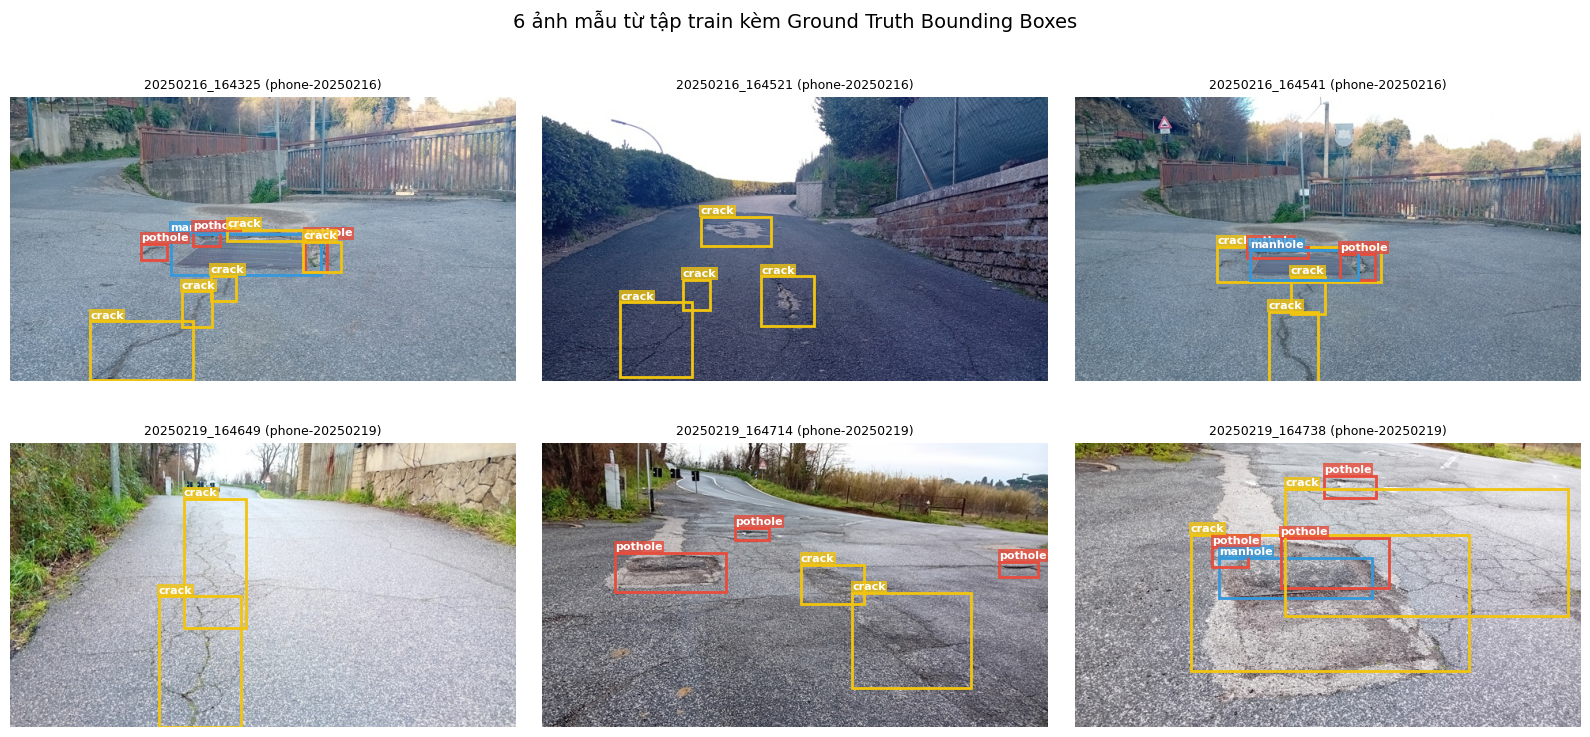

In [10]:
# Trực quan hóa 6 ảnh mẫu kèm bounding box nhãn từ tập train
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

color_map = {"pothole": "#e74c3c", "crack": "#f1c40f", "manhole": "#3498db"}

for i, sample in enumerate(train_entries[:6]):
    img_path = Path("data") / sample["image_path"]
    img = Image.open(img_path).convert("RGB")
    w, h = img.size

    ax = axes[i]
    ax.imshow(img)
    ax.set_title(f"{sample['image_id']} ({sample['session']})", fontsize=9)
    ax.axis("off")

    for obj in sample["objects"]:
        xc, yc, bw, bh = obj["yolo"]
        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        box_w = bw * w
        box_h = bh * h
        color = color_map.get(obj["label"], "white")

        rect = patches.Rectangle((x1, y1), box_w, box_h, linewidth=2, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, max(0, y1 - 4), obj["label"], color="white", fontsize=8, weight="bold",
                bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))

plt.suptitle("6 ảnh mẫu từ tập train kèm Ground Truth Bounding Boxes", fontsize=14)
plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

Chuyển đổi nhãn từ định dạng YOLO `[xc, yc, w, h]` chuẩn hoá `[0,1]` sang JSON list với toạ độ nguyên thang 0–1000 theo quy ước grounding của Qwen3-VL.

In [11]:
import json

def yolo_to_box(label, yolo):
    """
    Chuyển toạ độ YOLO [xc, yc, w, h] chuẩn hoá [0,1] sang box [x1, y1, x2, y2] thang 0-1000.
    Làm tròn thành số nguyên và kẹp trong [0, 1000].
    """
    xc, yc, w, h = yolo
    x1 = round(max(0.0, min(1000.0, (xc - w / 2) * 1000)))
    y1 = round(max(0.0, min(1000.0, (yc - h / 2) * 1000)))
    x2 = round(max(0.0, min(1000.0, (xc + w / 2) * 1000)))
    y2 = round(max(0.0, min(1000.0, (yc + h / 2) * 1000)))
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    """
    Chuyển danh sách objects thành chuỗi JSON list.
    Sắp xếp các box theo (y1, x1): trên -> dưới, trái -> phải để ổn định thứ tự output cho model.
    """
    boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"))

# Định nghĩa prompt chuẩn grounding
PROMPT = (
    "Locate road damage objects in this image. "
    "Classes: pothole, crack, manhole. "
    "Output a JSON list of objects: [{\"label\": \"<class>\", \"bbox_2d\": [x1, y1, x2, y2]}]. "
    "Coordinates must be integers on a 0-1000 scale. Return ONLY the JSON list, no extra text."
)

print("Prompt grounding:")
print(PROMPT)

Prompt grounding:
Locate road damage objects in this image. Classes: pothole, crack, manhole. Output a JSON list of objects: [{"label": "<class>", "bbox_2d": [x1, y1, x2, y2]}]. Coordinates must be integers on a 0-1000 scale. Return ONLY the JSON list, no extra text.


In [12]:
# Kiểm tra tính chuẩn xác của hàm chuyển đổi (Roundtrip test)
sample = train_entries[0]
ans_json = objects_to_answer(sample["objects"])
parsed_boxes = json.loads(ans_json)

print(f"Ảnh ID: {sample['image_id']}")
print(f"JSON đáp án (thang 0-1000):\n{ans_json}\n")

w, h = sample["width"], sample["height"]

# Sắp xếp lại danh sách gốc theo cùng tiêu chí (y1, x1) để đối chiếu chính xác
sorted_orig_objects = sorted(
    sample["objects"],
    key=lambda o: (
        (o["yolo"][1] - o["yolo"][3] / 2) * 1000,
        (o["yolo"][0] - o["yolo"][2] / 2) * 1000
    )
)

for orig, pb in zip(sorted_orig_objects, parsed_boxes):
    xc, yc, bw, bh = orig["yolo"]
    gx1, gy1 = (xc - bw / 2) * w, (yc - bh / 2) * h
    gx2, gy2 = (xc + bw / 2) * w, (yc + bh / 2) * h

    px1, py1 = pb["bbox_2d"][0] * w / 1000.0, pb["bbox_2d"][1] * h / 1000.0
    px2, py2 = pb["bbox_2d"][2] * w / 1000.0, pb["bbox_2d"][3] * h / 1000.0

    assert abs(gx1 - px1) <= 1.0 and abs(gy1 - py1) <= 1.0
    assert abs(gx2 - px2) <= 1.0 and abs(gy2 - py2) <= 1.0

print("✓ Xác nhận: Chuyển đổi hai chiều chính xác tuyệt đối (sai số làm tròn <= 1 pixel).")

Ảnh ID: 20250216_164325
JSON đáp án (thang 0-1000):
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]

✓ Xác nhận: Chuyển đổi hai chiều chính xác tuyệt đối (sai số làm tròn <= 1 pixel).


## 3. E0 — Zero-shot, ViT không NF4

Dùng `llm_int8_skip_modules=['model.visual','visual','lm_head']` cho NF4. Kiểm tra module và số projector trước khi đánh giá. Không sử dụng `pip upgrade` ngay trong cell vì sẽ thay đổi môi trường sau khi import `transformers`.

In [13]:
# Cell 13 — Cấu hình mô hình dùng CHUNG cho E0–E4
import re, gc
import torch
import bitsandbytes as bnb
from transformers import AutoProcessor, BitsAndBytesConfig, AutoModelForImageTextToText

MODEL_ID = 'Qwen/Qwen3-VL-4B-Instruct'
SKIP_4BIT = ['model.visual', 'visual', 'lm_head']
PROJECTOR_PATHS = ('visual.merger.', 'visual.deepstack_merger_list.')

def compute_dtype():
    return torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

def make_bnb_config(dtype):
    return BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type='nf4',
        bnb_4bit_compute_dtype=dtype,
        bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=SKIP_4BIT,
    )

def is_projector_param(name):
    return any(path in name for path in PROJECTOR_PATHS)

def check_vision(base_model):
    wrong = [n for n, m in base_model.named_modules()
             if 'visual' in n.split('.') and isinstance(m, bnb.nn.Linear4bit)]
    if wrong:
        raise RuntimeError('Có lớp vision bị NF4: ' + str(wrong[:8]))
    nproj = sum(p.numel() for n, p in base_model.named_parameters()
                if is_projector_param(n))
    print(f'[preflight] Projector parameters: {nproj:,}')
    if not (100_000_000 <= nproj <= 120_000_000):
        raise RuntimeError('Projector không khoảng 109M tham số; kiểm tra tên module/quantization.')
    return nproj

def load_base_model(model_id=MODEL_ID):
    dtype = compute_dtype()
    base = AutoModelForImageTextToText.from_pretrained(
        model_id,
        quantization_config=make_bnb_config(dtype),
        torch_dtype=dtype,
        device_map={'': 0},
    )
    check_vision(base)
    return base

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = 'left'
print('Precision:', compute_dtype(), '| skip NF4:', SKIP_4BIT)
model = load_base_model()

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

[preflight] Projector parameters: 109,105,152


In [14]:
# Cell 14 — Inference E0 (và hàm chung cho E1–E4)
from tqdm.auto import tqdm
from PIL import Image
from pathlib import Path
from scripts.labcommon import write_jsonl

@torch.inference_mode()
def run_inference(model, processor, entries, prompt, out_path, batch_size=2, max_new_tokens=256):
    model.eval()
    results = []
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    for i in tqdm(range(0, len(entries), batch_size), desc=f'Inference {out_path.name}'):
        batch = entries[i:i+batch_size]
        images = [Image.open(Path('data') / e['image_path']).convert('RGB') for e in batch]
        messages = [[{'role':'user','content':[
            {'type':'image','image':im}, {'type':'text','text':prompt}]}] for im in images]
        texts = [processor.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
                 for m in messages]
        inputs = processor(text=texts, images=images, padding=True,
                           return_tensors='pt').to('cuda')
        prompt_len = inputs.input_ids.shape[1]
        with torch.amp.autocast('cuda', dtype=compute_dtype()):
            outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        for j, item in enumerate(batch):
            raw = processor.decode(outputs[j, prompt_len:], skip_special_tokens=True).strip()
            results.append({'image_id': item['image_id'], 'raw': raw})
        for im in images:
            im.close()
    write_jsonl(out_path, results)
    print(f'✓ Lưu {len(results)} dự đoán: {out_path}')
    return results

run_inference(model, processor, test_entries, PROMPT, 'work/e0.jsonl', batch_size=2)
del model
gc.collect()
torch.cuda.empty_cache()

Inference e0.jsonl:   0%|          | 0/156 [00:00<?, ?it/s]

✓ Lưu 311 dự đoán: work/e0.jsonl


In [15]:
# Chấm điểm E0 bằng trọng tài score.py
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.691 P=0.105 R=0.067 F1=0.082 CI95=0.059-0.107 meanIoU=0.609 FP/img=1.07
   pothole  P=0.333 R=0.083 F1=0.132
   crack    P=0.021 R=0.017 F1=0.019
   manhole  P=0.224 R=0.147 F1=0.178


In [16]:
# In 5 output thô của E0 để phân tích lỗi thường gặp của model gốc
from scripts.labcommon import read_jsonl
e0_preds = read_jsonl("work/e0.jsonl")
print("=== 5 OUTPUT THÔ TIÊU BIỂU CỦA E0 ===")
for r in e0_preds[:5]:
    print(f"Image ID: {r['image_id']}\nRaw Output: {r['raw']}\n{'-'*50}")

=== 5 OUTPUT THÔ TIÊU BIỂU CỦA E0 ===
Image ID: vlcsnap-00200
Raw Output: [{"label": "manhole", "bbox_2d": [767, 640, 843, 684]}, {"label": "manhole", "bbox_2d": [909, 786, 997, 824]}]
--------------------------------------------------
Image ID: vlcsnap-00201
Raw Output: [{"label": "crack", "bbox_2d": [0, 450, 500, 500]}]
--------------------------------------------------
Image ID: vlcsnap-00202
Raw Output: [{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}, {"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]
--------------------------------------------------
Image ID: vlcsnap-00203
Raw Output: [{"label": "crack", "bbox_2d": [0, 476, 1000, 999]}]
--------------------------------------------------
Image ID: vlcsnap-00204
Raw Output: [{"label": "manhole", "bbox_2d": [257, 624, 325, 657]}]
--------------------------------------------------


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

Chuẩn bị Dataset, hàm mã hoá `encode_example` với mask loss (`labels = -100` trên prompt và vision tokens), và custom `collate_fn`.

In [17]:
import torch
from torch.utils.data import Dataset, DataLoader

def encode_example(processor, image, prompt, answer):
    """
    Mã hoá một cặp (image, prompt, answer) và gán nhãn mask loss:
    - prompt_enc: chỉ phần prompt của user
    - full_enc: chuỗi đầy đủ gồm user + assistant
    - labels: sao chép full_enc.input_ids và gán -100 cho tất cả token trước assistant response
    """
    user_msg = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": prompt},
            ],
        }
    ]
    prompt_text = processor.apply_chat_template(user_msg, tokenize=False, add_generation_prompt=True)
    prompt_enc = processor(text=[prompt_text], images=[image], return_tensors="pt")

    full_msg = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": prompt},
            ],
        },
        {
            "role": "assistant",
            "content": [{"type": "text", "text": answer}],
        },
    ]
    full_text = processor.apply_chat_template(full_msg, tokenize=False, add_generation_prompt=False)
    full_enc = processor(text=[full_text], images=[image], return_tensors="pt")

    prompt_len = prompt_enc.input_ids.shape[1]
    assert torch.equal(full_enc.input_ids[0, :prompt_len], prompt_enc.input_ids[0]), "Prompt phải là tiền tố của full sequence!"

    labels = full_enc.input_ids.clone()
    labels[0, :prompt_len] = -100  # Chỉ tính loss trên phần câu trả lời của assistant
    full_enc["labels"] = labels
    return full_enc

class RoadDamageDataset(Dataset):
    def __init__(self, entries, prompt, processor, data_dir="data"):
        self.entries = entries
        self.prompt = prompt
        self.processor = processor
        self.data_dir = Path(data_dir)

    def __len__(self):
        return len(self.entries)

    def __getitem__(self, idx):
        entry = self.entries[idx]
        img_path = self.data_dir / entry["image_path"]
        image = Image.open(img_path).convert("RGB")
        answer = objects_to_answer(entry["objects"])
        return encode_example(self.processor, image, self.prompt, answer)

def collate_fn(batch, pad_token_id):
    """
    Collate function đệm (pad) input_ids, attention_mask, labels đến cùng độ dài max_len trong batch.
    Nối (cat) pixel_values và image_grid_thw theo chiều 0 (KHÔNG pad).
    """
    max_len = max(ex.input_ids.shape[1] for ex in batch)

    input_ids_list, attention_mask_list, labels_list = [], [], []
    for ex in batch:
        cur_len = ex.input_ids.shape[1]
        pad_len = max_len - cur_len

        inp = torch.cat([ex.input_ids, torch.full((1, pad_len), pad_token_id, dtype=torch.long)], dim=1)
        att = torch.cat([ex.attention_mask, torch.zeros((1, pad_len), dtype=torch.long)], dim=1)
        lab = torch.cat([ex.labels, torch.full((1, pad_len), -100, dtype=torch.long)], dim=1)

        input_ids_list.append(inp)
        attention_mask_list.append(att)
        labels_list.append(lab)

    res = {
        "input_ids": torch.cat(input_ids_list, dim=0),
        "attention_mask": torch.cat(attention_mask_list, dim=0),
        "labels": torch.cat(labels_list, dim=0),
    }

    if hasattr(batch[0], "pixel_values") and batch[0].pixel_values is not None:
        res["pixel_values"] = torch.cat([ex.pixel_values for ex in batch], dim=0)
    if hasattr(batch[0], "image_grid_thw") and batch[0].image_grid_thw is not None:
        res["image_grid_thw"] = torch.cat([ex.image_grid_thw for ex in batch], dim=0)
    if hasattr(batch[0], "mm_token_type_ids") and batch[0].mm_token_type_ids is not None:
        mm_list = []
        for ex in batch:
            cur_len = ex.mm_token_type_ids.shape[1]
            pad_len = max_len - cur_len
            mm = torch.cat([ex.mm_token_type_ids, torch.zeros((1, pad_len), dtype=torch.long)], dim=1)
            mm_list.append(mm)
        res["mm_token_type_ids"] = torch.cat(mm_list, dim=0)

    return res

In [18]:
# Kiểm tra số token ảnh và tính chính xác của mask loss
sample_e = train_entries[0]
sample_img = Image.open(Path("data") / sample_e["image_path"]).convert("RGB")
enc_sample = encode_example(processor, sample_img, PROMPT, objects_to_answer(sample_e["objects"]))

img_pad_token_id = processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
count_img_tokens = (enc_sample.input_ids[0] == img_pad_token_id).sum().item()
print(f"Số token ảnh: {count_img_tokens} (Chuẩn cho 640x360: 220 token)")

loss_tokens = enc_sample.input_ids[0][enc_sample.labels[0] != -100]
decoded_target = processor.decode(loss_tokens)
print(f"\nNội dung được tính loss:\n{decoded_target}")

assert "<|im_end|>" in decoded_target or decoded_target.endswith("]")
print("\n✓ Xác nhận: Mask loss hoạt động chuẩn xác.")

Số token ảnh: 220 (Chuẩn cho 640x360: 220 token)

Nội dung được tính loss:
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>


✓ Xác nhận: Mask loss hoạt động chuẩn xác.


## 5. E1–E3 — LoRA/Projector

Chọn module LoRA theo **đường dẫn chính xác**: 252 lớp LLM; E3 thêm 96 lớp ViT. E2/E3 mở cả merger và deepstack_merger ở FP32. Kiểm tra số lượng trước khi huấn luyện để phát hiện quantization sai.

In [19]:
# Cell 21 — Setup PEFT: chính xác 252/348 module LoRA, projector FP32
import re, torch
from peft import LoraConfig, get_peft_model

LLM_TARGET_RE = re.compile(
    r'(?:^|\.)language_model(?:\.model)?\.layers\.\d+\.(?:'
    r'self_attn\.(?:q_proj|k_proj|v_proj|o_proj)|'
    r'mlp\.(?:gate_proj|up_proj|down_proj))$'
)
VIT_TARGET_RE = re.compile(
    r'(?:^|\.)visual\.blocks\.\d+\.(?:'
    r'attn\.(?:qkv|proj)|mlp\.(?:linear_fc1|linear_fc2))$'
)

def apply_setup(base_model, setup_name, cfg=None):
    cfg = cfg or {}
    check_vision(base_model)
    for p in base_model.parameters():
        p.requires_grad_(False)
    base_model.enable_input_require_grads()

    llm_targets = [n for n, _ in base_model.named_modules() if LLM_TARGET_RE.search(n)]
    vit_targets = [n for n, _ in base_model.named_modules() if VIT_TARGET_RE.search(n)]
    if len(llm_targets) != 252:
        raise RuntimeError(f'LLM LoRA modules={len(llm_targets)} != 252; ví dụ: {llm_targets[:6]}')
    if setup_name == 'E3' and len(vit_targets) != 96:
        raise RuntimeError(f'ViT LoRA modules={len(vit_targets)} != 96; ví dụ: {vit_targets[:6]}')
    if setup_name not in ('E1', 'E2', 'E3'):
        raise ValueError(f'Setup không hỗ trợ: {setup_name}')
    targets = llm_targets + (vit_targets if setup_name == 'E3' else [])
    lora_cfg = cfg.get('lora', {})
    r = int(lora_cfg.get('r', 16))
    alpha = int(lora_cfg.get('alpha', 2*r))
    dropout = float(lora_cfg.get('dropout', 0.05))
    peft_model = get_peft_model(base_model, LoraConfig(
        r=r, lora_alpha=alpha, lora_dropout=dropout,
        target_modules=targets, bias='none', task_type='CAUSAL_LM',
    ))
    active = [n for n, m in peft_model.named_modules()
              if n.endswith('.lora_A') and any(p.requires_grad for p in m.parameters())]
    expected = 348 if setup_name == 'E3' else 252
    print(f'[{setup_name}] LoRA active: {len(active)} (expected {expected}), rank={r}')
    if len(active) != expected:
        raise RuntimeError(f'Số lớp LoRA không đúng: {len(active)} != {expected}')

    # Bắt buộc trainable weights ở FP32, không ép chúng về BF16/FP16 ở train_setup.
    for name, p in peft_model.named_parameters():
        if p.requires_grad and 'lora_' in name:
            p.data = p.data.float()

    nproj = 0
    if setup_name in ('E2', 'E3'):
        for name, p in peft_model.named_parameters():
            if is_projector_param(name):
                if isinstance(p, bnb.nn.Params4bit):
                    raise RuntimeError(f'{name} vẫn ở Params4bit')
                p.data = p.data.float()
                p.requires_grad_(True)
                nproj += p.numel()
        if not (100_000_000 <= nproj <= 120_000_000):
            raise RuntimeError(f'Projector trainable count={nproj:,} không khoảng 109M')
    trainable = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in peft_model.parameters())
    print(f'[{setup_name}] projector FP32 = {nproj:,} params; trainable={trainable:,}/{total:,}')
    return peft_model

## 6. Huấn luyện

Optimizer AdamW: LoRA 2e-4, projector 1e-5; cosine scheduler, 5% warmup, batch size 2, gradient accumulation 4, `max_steps=300`. BF16 nếu GPU hỗ trợ; T4 dùng FP16+GradScaler. Trainable giữ FP32; autocast được dùng cho forward. Lưu LoRA cùng projector weights riêng sau mỗi 100 bước.

In [20]:
# Cell 23 — Training E1/E2/E3 và E4; tách LR projector; không đụng FP32 trainable
import gc, json, time, yaml
import torch
from pathlib import Path
from torch.optim import AdamW
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import get_cosine_schedule_with_warmup

def train_setup(setup_name, custom_cfg=None):
    cfg = custom_cfg
    if cfg is None:
        cfg = yaml.safe_load(Path(f'configs/{setup_name.lower()}.yaml').read_text(encoding='utf-8'))
    cfg = dict(cfg)
    run_name = str(cfg.get('name', setup_name)).lower()
    max_steps = int(cfg.get('max_steps', 300))
    grad_accum = int(cfg.get('grad_accum', 4))
    batch_size = int(cfg.get('batch_size', 2))
    assert max_steps > 0 and grad_accum > 0 and batch_size > 0
    if not torch.cuda.is_available():
        raise RuntimeError('Cần GPU để train')
    torch.manual_seed(int(cfg.get('seed', 42)))
    torch.cuda.manual_seed_all(int(cfg.get('seed', 42)))
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    print(f'\n=== TRAIN {run_name} ({cfg.get("description","")}) ===')
    dtype = compute_dtype()
    print('Compute dtype:', dtype)
    base_model = load_base_model(cfg.get('model_id', MODEL_ID))
    model = apply_setup(base_model, setup_name, cfg)
    if cfg.get('gradient_checkpointing', True):
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    model.config.use_cache = False

    named_trainable = [(n,p) for n,p in model.named_parameters() if p.requires_grad]
    wrong_dtype = [(n,str(p.dtype)) for n,p in named_trainable if p.dtype != torch.float32]
    if wrong_dtype:
        raise RuntimeError(f'Trainable không FP32: {wrong_dtype[:5]}')
    trainable_params = sum(p.numel() for _,p in named_trainable)
    proj_params = [p for n,p in named_trainable if is_projector_param(n)]
    lora_params = [p for n,p in named_trainable if not is_projector_param(n)]
    assert lora_params
    lora_lr = float(cfg.get('lr', 2e-4))
    projector_lr = float(cfg.get('projector_lr', 1e-5))
    groups = [{'params': lora_params, 'lr': lora_lr}]
    if proj_params:
        groups.append({'params': proj_params, 'lr': projector_lr})
    optimizer = AdamW(groups, weight_decay=0.0)
    scheduler = get_cosine_schedule_with_warmup(
        optimizer, num_warmup_steps=max(1,int(max_steps * 0.05)),
        num_training_steps=max_steps,
    )
    scaler = torch.amp.GradScaler('cuda') if dtype == torch.float16 else None
    print(f'LR LoRA={lora_lr:g}, projector={projector_lr:g}; grad_accum={grad_accum}')

    ds = RoadDamageDataset(train_entries, PROMPT, processor)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True,
                        collate_fn=lambda b: collate_fn(b, processor.tokenizer.pad_token_id))
    iterator = iter(loader)
    out_dir = Path('work') / f'checkpoint_{run_name}'
    out_dir.mkdir(parents=True, exist_ok=True)
    started = time.monotonic()
    global_step, acc_loss = 0, 0.0
    model.train()
    optimizer.zero_grad(set_to_none=True)
    pbar = tqdm(total=max_steps, desc=f'Train {run_name}')
    try:
        while global_step < max_steps:
            for micro in range(grad_accum):
                try:
                    batch = next(iterator)
                except StopIteration:
                    iterator = iter(loader)
                    batch = next(iterator)
                batch = {k:v.to('cuda', non_blocking=True) for k,v in batch.items()}
                if not (batch['labels'] != -100).any().item():
                    raise RuntimeError('Batch có labels toàn -100')
                with torch.amp.autocast('cuda', dtype=dtype):
                    loss = model(**batch).loss
                    scaled_loss = loss / grad_accum
                if not torch.isfinite(loss).item():
                    raise RuntimeError(f'NaN/Inf forward at step={global_step}, micro={micro}')
                acc_loss += float(loss.detach().item())
                if scaler is not None:
                    scaler.scale(scaled_loss).backward()
                else:
                    scaled_loss.backward()
                del loss, scaled_loss

            if scaler is not None:
                scaler.unscale_(optimizer)
            try:
                norm = torch.nn.utils.clip_grad_norm_(
                    [p for _,p in named_trainable], max_norm=1.0, error_if_nonfinite=True)
            except RuntimeError as e:
                bad = [n for n,p in named_trainable if p.grad is not None and
                       not torch.isfinite(p.grad).all().item()][:8]
                raise RuntimeError(f'NaN/Inf gradients at step={global_step}: {bad}') from e
            if scaler is not None:
                scaler.step(optimizer); scaler.update()
            else:
                optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            global_step += 1
            pbar.update(1)
            pbar.set_postfix(loss=f'{acc_loss/grad_accum:.4f}',
                             lr=f'{scheduler.get_last_lr()[0]:.2e}',
                             grad_norm=f'{norm.item():.2f}')
            acc_loss = 0.0
            if global_step % 100 == 0 or global_step == max_steps:
                model.save_pretrained(out_dir)
                if cfg.get('train_projector', False):
                    weights = {n:p.detach().cpu().clone() for n,p in model.named_parameters()
                               if is_projector_param(n)}
                    assert sum(v.numel() for v in weights.values()) > 100_000_000
                    torch.save(weights, out_dir / 'projector_weights.pt')
                    del weights
                print(f'[checkpoint] step={global_step}, path={out_dir}')
    finally:
        pbar.close()
    elapsed = (time.monotonic()-started)/60
    peak = torch.cuda.max_memory_allocated() / (1024**3)
    meta = {'trainable_params':int(trainable_params),
            'peak_vram_gb':round(peak,3), 'train_minutes':round(elapsed,3),
            'adapter_lr':lora_lr,
            'projector_lr':projector_lr if proj_params else None,
            'model_dtype':str(dtype), 'steps':global_step}
    (Path('work') / f'{run_name}_run.json').write_text(
        json.dumps(meta, indent=2, ensure_ascii=False), encoding='utf-8')
    print(f'✓ {run_name} complete: steps={global_step}, VRAM={peak:.2f}GiB, minutes={elapsed:.2f}')
    del model, base_model, optimizer, scheduler, iterator, loader
    if scaler is not None: del scaler
    gc.collect(); torch.cuda.empty_cache()
    return meta, out_dir

## 7. Suy luận và chấm

Tải lại base NF4 với ViT không lượng tử hóa, LoRA adapter và **projector FP32** (E2/E3), chấm test split qua `scripts/score.py`. Không sửa grader. Nếu muốn gỡ lỗi, chạy `evaluate_and_score(..., split='val')`.

In [21]:
# Cell 25 — Eval E1/E2/E3/E4 với đúng projector đã huấn luyện
import subprocess, sys, gc
from pathlib import Path
from peft import PeftModel
import torch

def evaluate_and_score(setup_name, save_dir, run_meta, coord='norm1000',
                       custom_name=None, split='test'):
    assert split in ('val','test')
    ev_name = custom_name or setup_name
    print(f'\n=== EVALUATE {ev_name} / {split} ===')
    gc.collect(); torch.cuda.empty_cache()
    base_model = load_base_model()
    model = PeftModel.from_pretrained(base_model, save_dir)
    path = Path(save_dir) / 'projector_weights.pt'
    if setup_name in ('E2','E3') and not path.exists():
        raise FileNotFoundError(f'Thiếu projector checkpoint: {path}')
    if path.exists():
        weights = torch.load(path, map_location='cpu', weights_only=True)
        available = dict(model.named_parameters())
        missing = [n for n in weights if n not in available]
        if missing:
            raise RuntimeError(f'Tên tham số projector không khớp: {missing[:6]}')
        count = sum(v.numel() for v in weights.values())
        if not (100_000_000 <= count <= 120_000_000):
            raise RuntimeError(f'Projector checkpoint thiếu tham số: {count:,}')
        with torch.no_grad():
            for n, value in weights.items():
                target = available[n]
                target.data = value.to(device=target.device, dtype=torch.float32).contiguous()
        print(f'✓ Restored FP32 projector: {count:,} params')
        del weights
    pred_path = f'work/{ev_name.lower()}_{split}.jsonl' if split != 'test' else f'work/{ev_name.lower()}.jsonl'
    entries = val_entries if split == 'val' else test_entries
    run_inference(model, processor, entries, PROMPT, pred_path, batch_size=2)
    ev_path = Path('report/evidence') / (f'{ev_name.lower()}_{split}.json' if split != 'test' else f'{ev_name.lower()}.json')
    cmd = [sys.executable, 'scripts/score.py', '--pred', pred_path,
           '--split', split, '--name', ev_name, '--out', str(ev_path), '--coord', coord]
    for key in ('trainable_params','peak_vram_gb','train_minutes'):
        cmd += ['--meta', f'{key}={run_meta[key]}']
    subprocess.run(cmd, check=True)
    del model, base_model
    gc.collect(); torch.cuda.empty_cache()
    return ev_path

In [22]:
# Cell 26 — Train/score E1 (run once)
e1_meta, e1_dir = train_setup('E1')
evaluate_and_score('E1', e1_dir, e1_meta)


=== TRAIN e1 (LoRA chỉ trên LLM; đóng băng ViT và projector.) ===
Compute dtype: torch.bfloat16


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[preflight] Projector parameters: 109,105,152
[preflight] Projector parameters: 109,105,152
[E1] LoRA active: 252 (expected 252), rank=16
[E1] projector FP32 = 0 params; trainable=33,030,144/2,654,188,032
LR LoRA=0.0002, projector=1e-05; grad_accum=4


Train e1:   0%|          | 0/300 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


...

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[preflight] Projector parameters: 109,105,152


Inference e1.jsonl:   0%|          | 0/156 [00:00<?, ?it/s]

✓ Lưu 311 dự đoán: work/e1.jsonl


PosixPath('report/evidence/e1.json')

In [26]:
# Cell 27 — Train/score E2, 300 optimizer steps. Bắt buộc xem preflight projector ~109M.
e2_meta, e2_dir = train_setup('E2')
evaluate_and_score('E2', e2_dir, e2_meta)


=== TRAIN e2 (E1 + mở đầy đủ projector (visual.merger và visual.deepstack_merger_list).) ===
Compute dtype: torch.bfloat16


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[preflight] Projector parameters: 109,105,152
[preflight] Projector parameters: 109,105,152
[E2] LoRA active: 252 (expected 252), rank=16
[E2] projector FP32 = 109,105,152 params; trainable=142,135,296/2,654,188,032
LR LoRA=0.0002, projector=1e-05; grad_accum=4


Train e2:   0%|          | 0/300 [00:00<?, ?it/s]

[checkpoint] step=100, path=work/checkpoint_e2
[checkpoint] step=200, path=work/checkpoint_e2
[checkpoint] step=300, path=work/checkpoint_e2
✓ e2 complete: steps=300, VRAM=11.74GiB, minutes=17.65

=== EVALUATE E2 / test ===


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[preflight] Projector parameters: 109,105,152
✓ Restored FP32 projector: 109,105,152 params


Inference e2.jsonl:   0%|          | 0/156 [00:00<?, ?it/s]

✓ Lưu 311 dự đoán: work/e2.jsonl


PosixPath('report/evidence/e2.json')

In [ ]:
# Cell 28 — Train/score E3
e3_meta, e3_dir = train_setup('E3')
evaluate_and_score('E3', e3_dir, e3_meta)

## 8. E4 rank ablation / E5 bonus

E4 thay đúng rank (và alpha=2r) so với một setup tốt nhất E1/E2/E3 chọn bằng **validation**, chạy `r=4` và `r=64`. Không ghi đè checkpoint E1. E5 trong file gốc chỉ có **reward IoU và unit tests**; phần huấn luyện GRPO là tùy chọn và chưa được thêm.

In [27]:
# Cell 30 — Ablation đúng yêu cầu: r=4 và r=64; không ghi đè checkpoint E1
import copy, yaml
from pathlib import Path
# Đổi E1 -> E2/E3 nếu kết quả VAL cho thấy setup đó tốt nhất.
BEST_SETUP = 'E1'
base_cfg = yaml.safe_load(Path(f'configs/{BEST_SETUP.lower()}.yaml').read_text(encoding='utf-8'))
for r in (4, 64):
    cfg = copy.deepcopy(base_cfg)
    cfg['name'] = f'E4_rank_{r}'
    cfg['lora']['r'] = r
    cfg['lora']['alpha'] = 2*r
    run_meta, ckpt = train_setup(BEST_SETUP, custom_cfg=cfg)
    evaluate_and_score(BEST_SETUP, ckpt, run_meta, custom_name=cfg['name'])


=== TRAIN e4_rank_4 (LoRA chỉ trên LLM; đóng băng ViT và projector.) ===
Compute dtype: torch.bfloat16


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[preflight] Projector parameters: 109,105,152
[preflight] Projector parameters: 109,105,152
[E1] LoRA active: 252 (expected 252), rank=4
[E1] projector FP32 = 0 params; trainable=8,257,536/2,629,415,424
LR LoRA=0.0002, projector=1e-05; grad_accum=4


Train e4_rank_4:   0%|          | 0/300 [00:00<?, ?it/s]

[checkpoint] step=100, path=work/checkpoint_e4_rank_4


...

[checkpoint] step=100, path=work/checkpoint_e4_rank_64
[checkpoint] step=200, path=work/checkpoint_e4_rank_64
[checkpoint] step=300, path=work/checkpoint_e4_rank_64
✓ e4_rank_64 complete: steps=300, VRAM=11.55GiB, minutes=18.77

=== EVALUATE E4_rank_64 / test ===


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[preflight] Projector parameters: 109,105,152


Inference e4_rank_64.jsonl:   0%|          | 0/156 [00:00<?, ?it/s]

✓ Lưu 311 dự đoán: work/e4_rank_64.jsonl


In [28]:
# ----------------- THÍ NGHIỆM E5 (BONUS): GRPO VỚI REWARD IOU -----------------
from scripts.score import parse_output, iou_xyxy

def compute_iou_reward(completion, gt_objects):
    """
    Hàm tính phần thưởng IoU cho GRPO:
    - JSON không parse được -> 0.0
    - Không có gt và không có pred -> 1.0
    - Ghép đôi tham lam theo IoU giảm dần, cùng lớp, ngưỡng IoU >= 0.5
    - Thưởng: 0.2 + 0.8 * (tổng IoU / max(số gt, số pred, 1))
    """
    pred = parse_output(completion)
    if pred is None:
        return 0.0

    gt_boxes = []
    for o in gt_objects:
        xc, yc, w, h = o["yolo"]
        gt_boxes.append({
            "label": o["label"],
            "bbox": ((xc - w / 2) * 1000, (yc - h / 2) * 1000, (xc + w / 2) * 1000, (yc + h / 2) * 1000)
        })

    n_gt = len(gt_boxes)
    n_pred = len(pred)

    if n_gt == 0 and n_pred == 0:
        return 1.0

    total_iou = 0.0
    for lab in {"pothole", "crack", "manhole"}:
        g = [x["bbox"] for x in gt_boxes if x["label"] == lab]
        p = [x["bbox"] for x in pred if x["label"] == lab]
        pairs = sorted(((iou_xyxy(a, b), i, j) for i, a in enumerate(g) for j, b in enumerate(p)), reverse=True)
        used_g, used_p = set(), set()
        for v, i, j in pairs:
            if v < 0.5:
                break
            if i in used_g or j in used_p:
                continue
            used_g.add(i)
            used_p.add(j)
            total_iou += v

    reward = 0.2 + 0.8 * (total_iou / max(n_gt, n_pred, 1))
    return reward

# UNIT TEST CHO HÀM REWARD (chạy kiểm tra không cần GPU)
def test_reward_function():
    gt = [{"label": "pothole", "yolo": [0.5, 0.5, 0.2, 0.2]}]
    # 1. Dự đoán hoàn hảo (IoU = 1.0) -> reward = 1.0
    perf = json.dumps([{"label": "pothole", "bbox_2d": [400, 400, 600, 600]}])
    assert abs(compute_iou_reward(perf, gt) - 1.0) < 1e-4

    # 2. JSON hỏng -> reward = 0.0
    assert compute_iou_reward("not a valid json", gt) == 0.0

    # 3. Sai lớp -> reward = 0.2 (0 IoU)
    wrong_cls = json.dumps([{"label": "crack", "bbox_2d": [400, 400, 600, 600]}])
    assert abs(compute_iou_reward(wrong_cls, gt) - 0.2) < 1e-4

    # 4. Thừa box giả mạo -> bị phạt mẫu số
    extra = json.dumps([{"label": "pothole", "bbox_2d": [400, 400, 600, 600]},
                        {"label": "crack", "bbox_2d": [10, 10, 50, 50]}])
    assert compute_iou_reward(extra, gt) < 1.0

    # 5. Cả 2 đều rỗng -> 1.0
    assert compute_iou_reward("[]", []) == 1.0
    print("✓ Tất cả các unit test cho hàm reward IoU đã vượt qua thành công!")

test_reward_function()

✓ Tất cả các unit test cho hàm reward IoU đã vượt qua thành công!


✓ Đã lưu ảnh trực quan hoá vào report/images/predictions_visualized.png


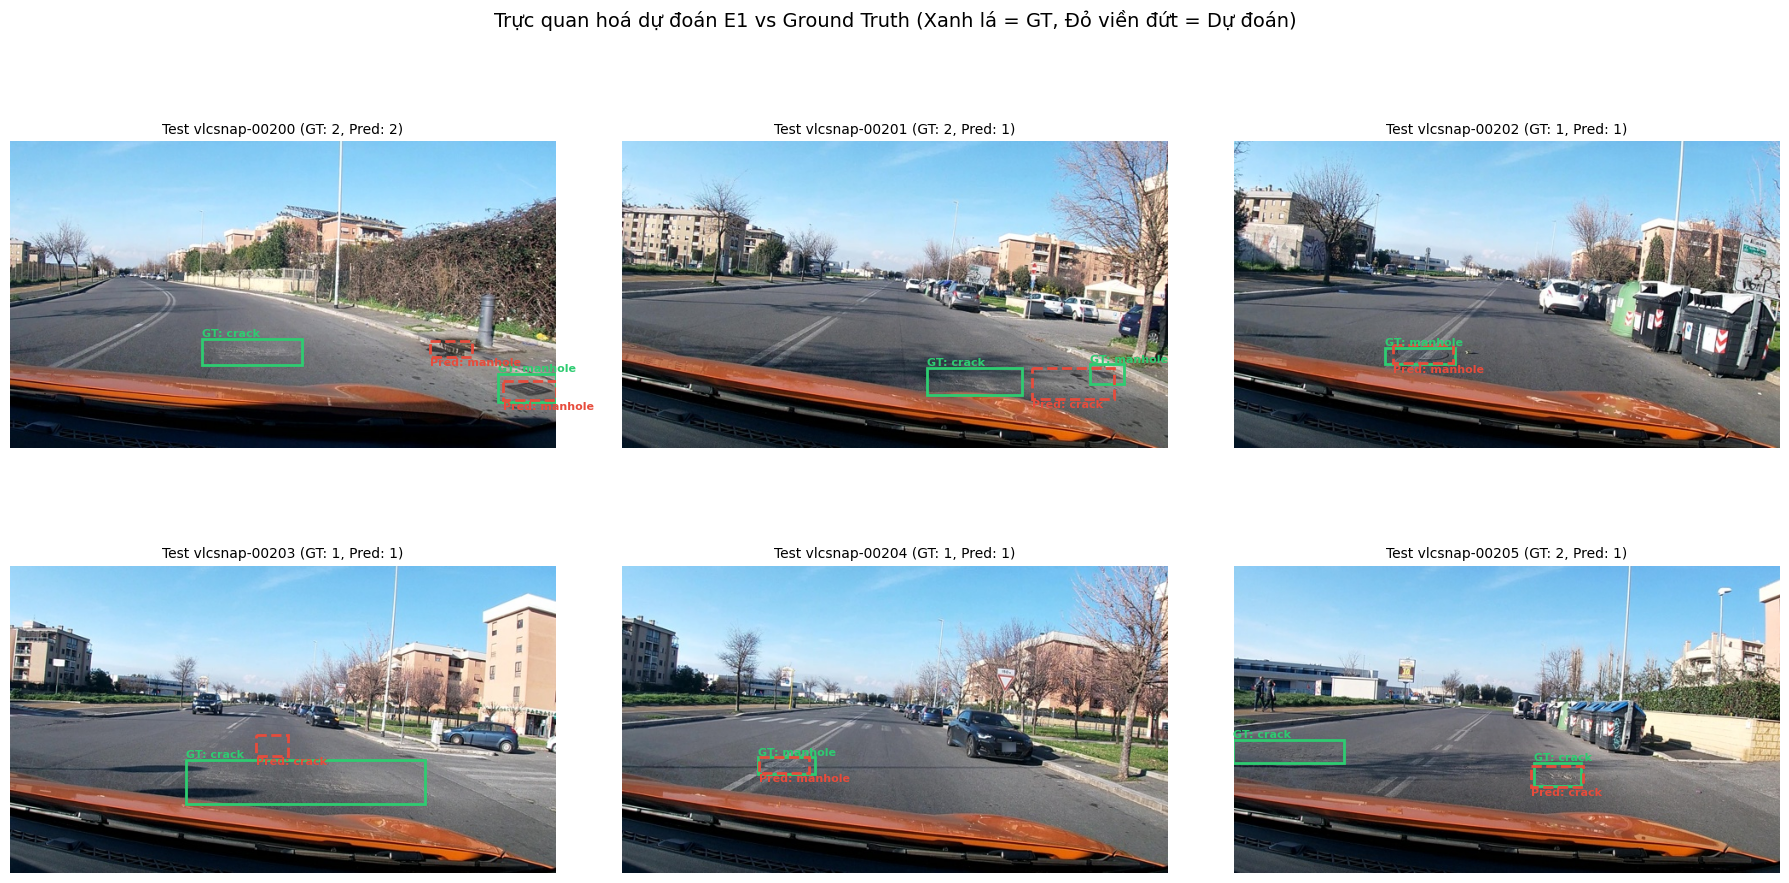

In [29]:
# ----------------- TRỰC QUAN HOÁ 6 ẢNH MINH HOẠ CHO BÁO CÁO -----------------
# Vẽ box Ground Truth (xanh lá) và Box Dự đoán (đỏ/vàng/xanh dương)
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from scripts.score import parse_output

report_img_dir = Path("report") / "images"
report_img_dir.mkdir(parents=True, exist_ok=True)

e1_preds_map = {r["image_id"]: r["raw"] for r in read_jsonl("work/e1.jsonl")}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, sample in enumerate(test_entries[:6]):
    im_path = Path("data") / sample["image_path"]
    im = Image.open(im_path).convert("RGB")
    w, h = im.size

    ax = axes[idx]
    ax.imshow(im)
    ax.axis("off")

    # Vẽ Ground Truth (Màu xanh lá)
    for obj in sample["objects"]:
        xc, yc, bw, bh = obj["yolo"]
        gx1, gy1 = (xc - bw / 2) * w, (yc - bh / 2) * h
        rect = patches.Rectangle((gx1, gy1), bw * w, bh * h, linewidth=2, edgecolor="#2ecc71", facecolor="none")
        ax.add_patch(rect)
        ax.text(gx1, max(0, gy1 - 3), f"GT: {obj['label']}", color="#2ecc71", fontsize=8, weight="bold")

    # Vẽ Dự đoán E1 (Màu đỏ nét đứt)
    raw_pred = e1_preds_map.get(sample["image_id"])
    pred_boxes = parse_output(raw_pred) or []
    for pb in pred_boxes:
        px1, py1, px2, py2 = pb["bbox"]
        rx1, ry1 = px1 * w / 1000.0, py1 * h / 1000.0
        rw, rh = (px2 - px1) * w / 1000.0, (py2 - py1) * h / 1000.0
        rect = patches.Rectangle((rx1, ry1), rw, rh, linewidth=2, edgecolor="#e74c3c", linestyle="--", facecolor="none")
        ax.add_patch(rect)
        ax.text(rx1, min(h, ry1 + rh + 10), f"Pred: {pb['label']}", color="#e74c3c", fontsize=8, weight="bold")

    ax.set_title(f"Test {sample['image_id']} (GT: {len(sample['objects'])}, Pred: {len(pred_boxes)})", fontsize=10)

plt.suptitle("Trực quan hoá dự đoán E1 vs Ground Truth (Xanh lá = GT, Đỏ viền đứt = Dự đoán)", fontsize=14)
plt.tight_layout()
sample_img_save_path = report_img_dir / "predictions_visualized.png"
plt.savefig(sample_img_save_path, dpi=200, bbox_inches="tight")
print(f"✓ Đã lưu ảnh trực quan hoá vào {sample_img_save_path}")
plt.show()

In [30]:
# ----------------- KIỂM TRA BÀI NỘP TRƯỚC KHI SUBMIT -----------------
!python scripts/check_submission.py

[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[FAIL] evidence e3 — thiếu report/evidence/e3.json
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[FAIL] git commits — 1/5
[PASS] git forbidden files

3 FAIL, 0 WARN
